# Netflix Audience Rating Classification

**Task 3 (Medium) | Auspify Technologies Machine Learning Internship**

In this task, I build a machine learning model that predicts the **audience rating category** (such as TV-MA, TV-14, PG-13 and R) of a Netflix title using its content attributes like type, genre, country, duration and release year.

This is a **multi-class classification** problem. I will compare Decision Tree and Random Forest models, optimize them with hyperparameter tuning, and evaluate them using classification metrics.


## 1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings

## 2. Loading the Dataset

In [2]:
df = pd.read_csv('Dataset.csv')

### 2.1 Analyzing the Dataset

In [3]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
df.tail()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
8785,s8797,TV Show,Yunus Emre,Not Given,Turkey,1/17/2017,2016,TV-PG,2 Seasons,"International TV Shows, TV Dramas"
8786,s8798,TV Show,Zak Storm,Not Given,United States,9/13/2018,2016,TV-Y7,3 Seasons,Kids' TV
8787,s8801,TV Show,Zindagi Gulzar Hai,Not Given,Pakistan,12/15/2016,2012,TV-PG,1 Season,"International TV Shows, Romantic TV Shows, TV ..."
8788,s8784,TV Show,Yoko,Not Given,Pakistan,6/23/2018,2016,TV-Y,1 Season,Kids' TV
8789,s8786,TV Show,YOM,Not Given,Pakistan,06/07/2018,2016,TV-Y7,1 Season,Kids' TV


### 2.2 Checking for the Missing, Duplicates and Unique Values

In [5]:
# Column names, data types and non-null counts
df.info()

# Missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Number of unique values in each column
print("\nUnique values per column:")
display(df.nunique())

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 1.6 MB

Missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate rows: 0

Unique values per column:


show_id         8790
type               2
title           8787
director        4528
country           86
date_added      1713
release_year      74
rating            14
duration         220
listed_in        513
dtype: int64

## 3. Step 1: Analyze Rating Categories

The `rating` column is our **target**, the thing the model must predict. Before building any model, I check how many categories it has and how balanced they are.

In [6]:
# Count and Percentage of each rating
rating_counts = df["rating"].value_counts()
rating_percent = (df["rating"].value_counts(normalize=True) * 100).round(2)

rating_summary = pd.DataFrame({
    "Count" : rating_counts,
    "Percentage (%)": rating_percent
})

print("Number of rating categories:", df["rating"].nunique())
display(rating_summary)

Number of rating categories: 14


,Count,Percentage (%)
rating,,
TV-MA,3205,36.46
TV-14,2157,24.54
TV-PG,861,9.80
R,799,9.09
PG-13,490,5.57
TV-Y7,333,3.79
TV-Y,306,3.48
PG,287,3.27
TV-G,220,2.50


### 3.1 Visualize Data via Charts

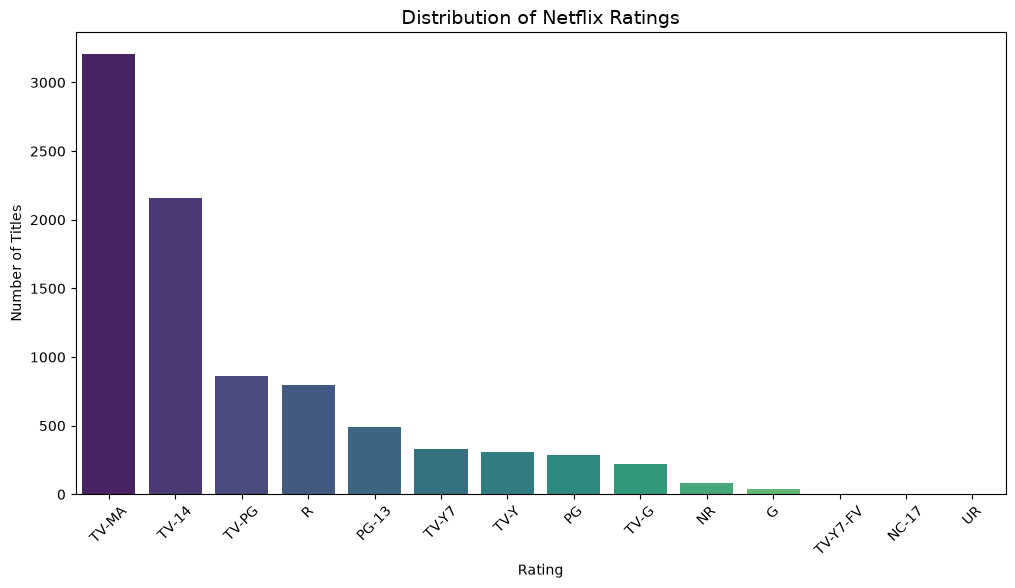

In [7]:
# Ignore the warning 
warnings.filterwarnings('ignore', category=FutureWarning)

# Bar chart of rating distribution
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x="rating", order=df["rating"].value_counts().index, palette="viridis")
plt.title("Distribution of Netflix Ratings", fontsize=14)
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

### 3.2 Comparing the Charts
Here we are going to compare the two columns like `Rating` and the `type` and then also create there comparison charts between the Movies and the TV shows

type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,730
TV-G,126,94
TV-MA,2062,1143


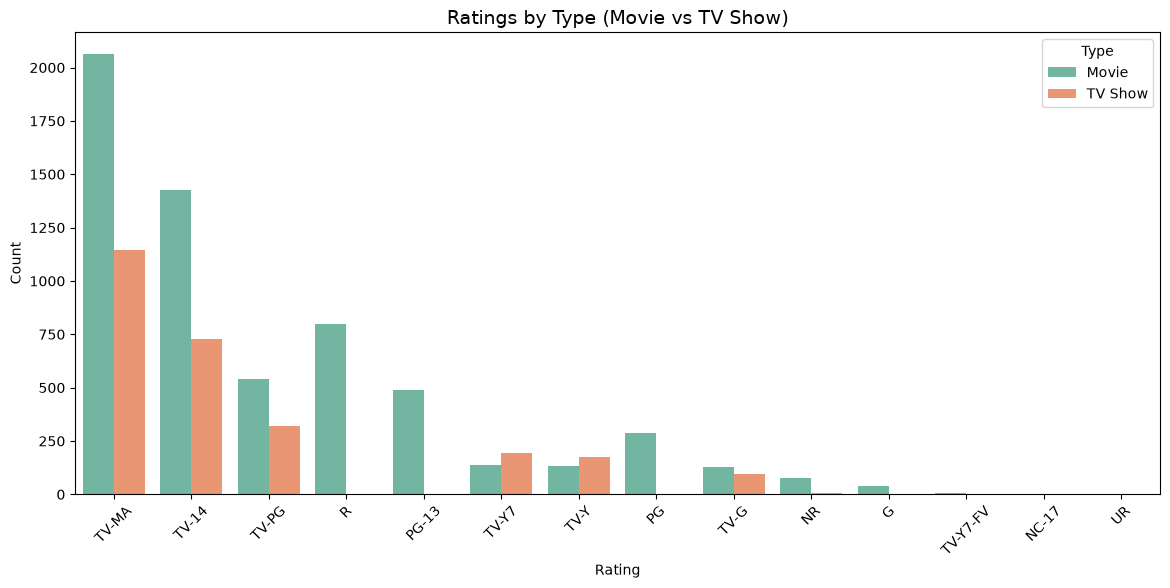

In [8]:
# How ratings are spread across Movies and TV Shows
rating_by_type = pd.crosstab(df["rating"], df["type"])
display(rating_by_type)

# Visual comparison
plt.figure(figsize=(14, 6))
sns.countplot(data=df, x="rating", hue="type", order=df["rating"].value_counts().index, palette="Set2")
plt.title("Ratings by Type (Movie vs TV Show)", fontsize=14)
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title="Type")
plt.show()

### 3.3 Checking the Rating less than 100 and Class Imbalance
Checking which ratings have very few titles. There is huge class imbalance in the dataset: TV-MA and TV-14 take up 61% of all titles, while G has only 41 titles and NR has 82 titles.

In [9]:
# Find the rare ratings (fewer than 100 titles)
rare_ratings = rating_counts[rating_counts < 100]
print("Rare ratings (less than 100 titles):")
display(rare_ratings)

Rare ratings (less than 100 titles):


rating
NR          79
G           41
TV-Y7-FV     6
NC-17        3
UR           3
Name: count, dtype: int64

## 4. Step 2: Prepare Training Datasets

### 4.1 Merging the Unique Values

In [10]:
# Work on a copy so the original df stays safe
data = df.copy()

# Merge the very rare ratings into their closest category
rating_merge = {
    "UR": "NR",           # Unrated = Not Rated
    "TV-Y7-FV": "TV-Y7",  # Fantasy Violence version of TV-Y7
    "NC-17": "R"          # both are adult-only movie ratings
}
data["rating"] = data["rating"].replace(rating_merge)

print("Rating categories after merging:", data["rating"].nunique())
print(data["rating"].value_counts())

Rating categories after merging: 11
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         802
PG-13     490
TV-Y7     339
TV-Y      306
PG        287
TV-G      220
NR         82
G          41
Name: count, dtype: int64


### 4.2 Feature Engineering

In [11]:
# duration: convert text like "90 min" or "2 Seasons" into a number
data["duration_num"] = data["duration"].str.extract(r"(\d+)").astype(float)

# separate movie minutes from tv show seasons so the numbers make sense
data["is_movie"] = (data["type"] == "Movie").astype(int)
data["movie_duration"] = np.where(data["is_movie"] == 1, data["duration_num"], 0)
data["tv_seasons"] = np.where(data["is_movie"] == 0, data["duration_num"], 0)

# date_added: extract the year and month
data["date_added"] = pd.to_datetime(data["date_added"], errors="coerce")
data["year_added"] = data["date_added"].dt.year
data["month_added"] = data["date_added"].dt.month

# content age: difference between added year and release year
data["years_diff"] = (data["year_added"] - data["release_year"]).clip(lower=0)

# director: check if director is given or not
data["has_director"] = (data["director"] != "Not Given").astype(int)

# distinguish US theatrical movies from international/tv titles
# US movies are much more likely to have MPAA ratings (R, PG-13, PG)
data["is_us_movie"] = ((data["is_movie"] == 1) & (data["country"].str.contains("United States", na=False))).astype(int)
data["is_international"] = data["listed_in"].str.contains("International", case=False, na=False).astype(int)

# country: keep the top 20 countries, group the rest as "Other"
data["main_country"] = data["country"].str.split(",").str[0].str.strip()
top_countries = data["main_country"].value_counts().head(20).index
data["main_country"] = data["main_country"].where(data["main_country"].isin(top_countries), "Other")

# genres: keep all genres as 0/1 columns instead of dropping any
genre_df = data["listed_in"].str.get_dummies(sep=", ")

# genre helper features for kids, mature, and comedy
data["is_kids"] = data["listed_in"].str.contains("Children|Kids", case=False, na=False).astype(int)
data["is_mature_genre"] = data["listed_in"].str.contains("Horror|Crime|Thrillers", case=False, na=False).astype(int)
data["is_standup"] = data["listed_in"].str.contains("Stand-Up Comedy", case=False, na=False).astype(int)
data["genre_count"] = genre_df.sum(axis=1)

print("Number of genres used as features:", genre_df.shape[1])
print("Sample genre columns:", list(genre_df.columns[:5]))

Number of genres used as features: 42
Sample genre columns: ['Action & Adventure', 'Anime Features', 'Anime Series', 'British TV Shows', 'Children & Family Movies']


### 4.3 Build (X, y)

In [12]:
# Numerical features
num_features = data[["release_year", "movie_duration", "tv_seasons", "year_added", "month_added", "years_diff", "has_director", "is_us_movie", "is_international", "is_kids", "is_mature_genre", "is_standup", "genre_count"]]

# Categorical features -> numbers (one-hot encoding)
cat_features = pd.get_dummies(data[["type", "main_country"]]).astype(int)

# Combine everything into the input table X
X = pd.concat([num_features, cat_features, genre_df], axis=1)
X = X.fillna(X.median())

# Target y: encode the rating text into numbers
le = LabelEncoder()
y = le.fit_transform(data["rating"])

print("X shape:", X.shape)
print("Missing values in X:", X.isnull().sum().sum())
print("\nRating -> number mapping:")
print(dict(zip(le.classes_, range(len(le.classes_)))))

X shape: (8790, 78)
Missing values in X: 0

Rating -> number mapping:
{'G': 0, 'NR': 1, 'PG': 2, 'PG-13': 3, 'R': 4, 'TV-14': 5, 'TV-G': 6, 'TV-MA': 7, 'TV-PG': 8, 'TV-Y': 9, 'TV-Y7': 10}


### 4.4 Train/Test Split

In [13]:
# 80% for training, 20% for testing; stratify keeps rating proportions equal in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (7032, 78)
Testing set : (1758, 78)


## 5. Step 3: Train Classification Models

I train two baseline models with default settings: a Decision Tree and a Random Forest.

In [14]:
# Decision Tree (baseline)
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

# Random Forest (baseline)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Compare training vs testing accuracy
for name, model in [("Decision Tree", dt), ("Random Forest", rf)]:
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{name:15s} | Train accuracy: {train_acc:.4f} | Test accuracy: {test_acc:.4f}")

Decision Tree   | Train accuracy: 0.9920 | Test accuracy: 0.4653
Random Forest   | Train accuracy: 0.9919 | Test accuracy: 0.5592


## 6. Step 4: Optimize Model Performance

I use **GridSearchCV** to test hyperparameter combinations and handle class imbalance using balanced weights. (This may take around a minute.)

In [15]:
# Tune the Decision Tree
dt_params = {
    "max_depth": [6, 10, 15, None],
    "min_samples_split": [2, 10, 20],
    "class_weight": [None, "balanced"]
}
dt_grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
                       dt_params, cv=3, scoring="accuracy", n_jobs=-1)
dt_grid.fit(X_train, y_train)

print("Best Decision Tree settings:", dt_grid.best_params_)
print("Best cross-validation accuracy:", round(dt_grid.best_score_, 4))

Best Decision Tree settings: {'class_weight': None, 'max_depth': 10, 'min_samples_split': 20}
Best cross-validation accuracy: 0.5156


In [16]:
# Tune the Random Forest
rf_params = {
    "n_estimators": [150, 250],
    "max_depth": [14, 20, 25],
    "min_samples_split": [2, 5],
    "class_weight": [None, "balanced"]
}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42),
                       rf_params, cv=3, scoring="accuracy", n_jobs=-1)
rf_grid.fit(X_train, y_train)

print("Best Random Forest settings:", rf_grid.best_params_)
print("Best cross-validation accuracy:", round(rf_grid.best_score_, 4))

Best Random Forest settings: {'class_weight': None, 'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 250}
Best cross-validation accuracy: 0.5694


## 7. Step 5: Evaluate Prediction Accuracy

,Model,Test Accuracy
0,Random Forest (Tuned),0.575085
1,Random Forest (Baseline),0.559158
2,Decision Tree (Tuned),0.520478
3,Decision Tree (Baseline),0.465301


Best model: Random Forest (Tuned)


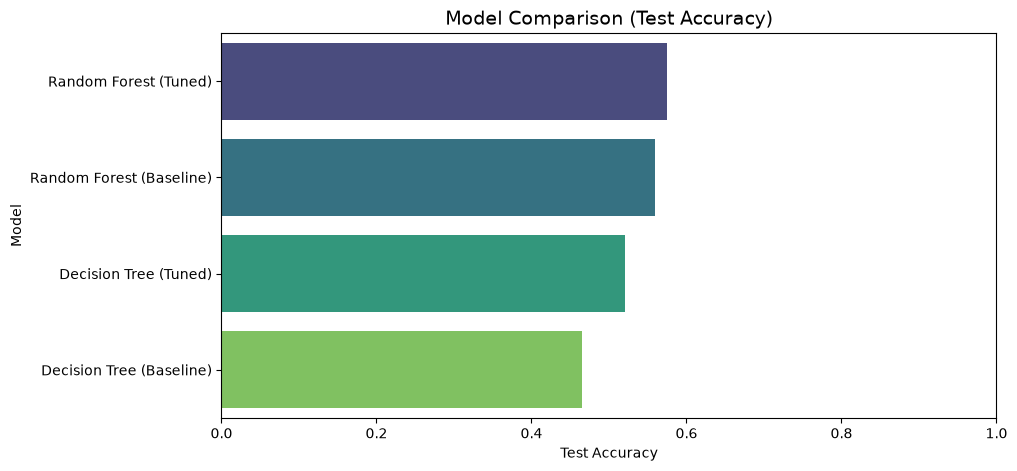

In [17]:
# Put all four models together
models = {
    "Decision Tree (Baseline)": dt,
    "Random Forest (Baseline)": rf,
    "Decision Tree (Tuned)": dt_grid.best_estimator_,
    "Random Forest (Tuned)": rf_grid.best_estimator_
}

results = pd.DataFrame({
    "Model": list(models.keys()),
    "Test Accuracy": [accuracy_score(y_test, m.predict(X_test)) for m in models.values()]
}).sort_values("Test Accuracy", ascending=False).reset_index(drop=True)

display(results)

# Pick the best model automatically
best_name = results.loc[0, "Model"]
final_model = models[best_name]
print("Best model:", best_name)

# Bar chart
plt.figure(figsize=(10, 5))
sns.barplot(data=results, x="Test Accuracy", y="Model", palette="viridis")
plt.title("Model Comparison (Test Accuracy)", fontsize=14)
plt.xlim(0, 1)
plt.show()

### 7.1 Classification Report

In [18]:
y_pred = final_model.predict(X_test)

print("Final model:", best_name)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

Final model: Random Forest (Tuned)
Accuracy: 0.5751

Classification Report:

              precision    recall  f1-score   support

           G       1.00      0.62      0.77         8
          NR       0.00      0.00      0.00        17
          PG       0.63      0.55      0.59        58
       PG-13       0.57      0.42      0.48        98
           R       0.61      0.61      0.61       160
       TV-14       0.53      0.48      0.50       431
        TV-G       0.50      0.02      0.04        44
       TV-MA       0.60      0.80      0.69       641
       TV-PG       0.40      0.20      0.27       172
        TV-Y       0.55      0.67      0.60        61
       TV-Y7       0.58      0.62      0.60        68

    accuracy                           0.58      1758
   macro avg       0.54      0.45      0.47      1758
weighted avg       0.56      0.58      0.55      1758



### 7.2 Confusion Matrix

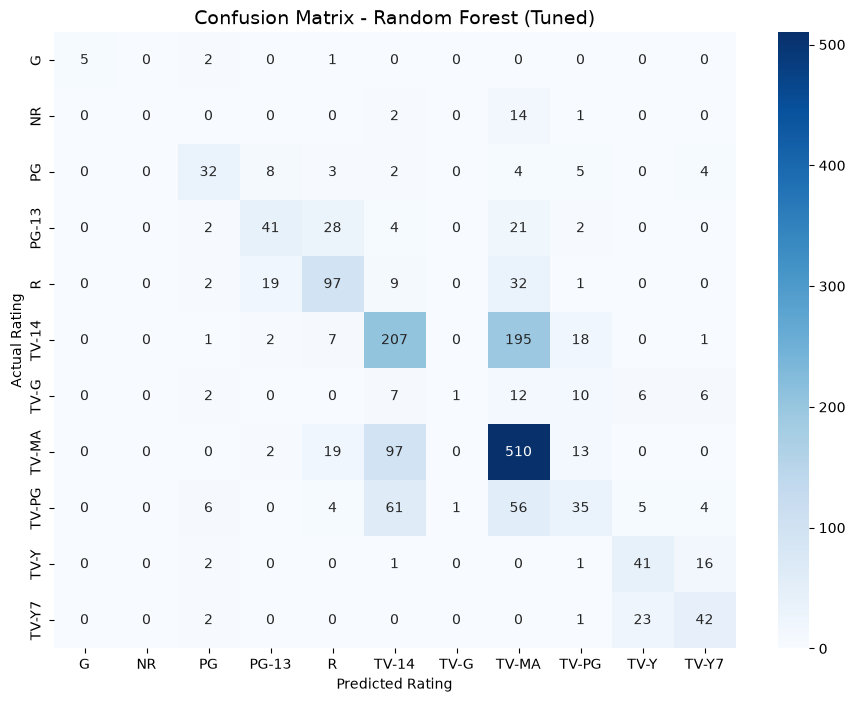

In [19]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(11, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix - " + best_name, fontsize=14)
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.show()

### 7.3 Feature Importance

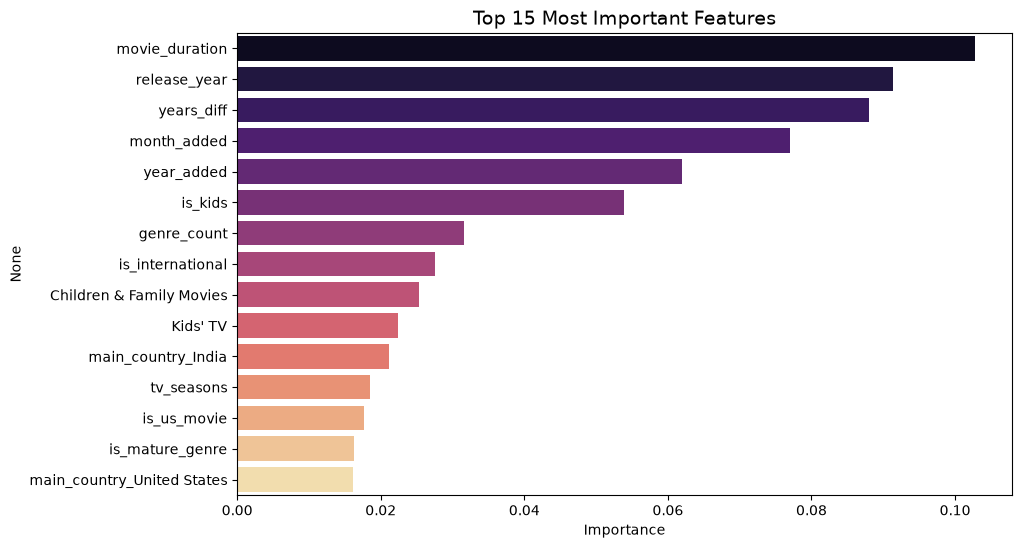

In [20]:
importances = pd.Series(final_model.feature_importances_, index=X.columns)
top_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_features.values, y=top_features.index, palette="magma")
plt.title("Top 15 Most Important Features", fontsize=14)
plt.xlabel("Importance")
plt.show()

## 8. Analyzing the Penalty and Audience Maturity Groups

Why does the model hit an accuracy ceiling around 57% on raw ratings?
Because rating labels have overlap:
- TV-MA (TV rating) and R (MPAA film rating) both mean Adults 18+.
- TV-14 and PG-13 both mean Teens 14+.
- TV-PG and PG both mean Parental Guidance.
- TV-Y, TV-Y7, TV-G, G all mean Kids.

When the true rating is R and the model predicts TV-MA, it is practically correct for audience suitability, but machine learning marks it as wrong (penalty).
If we group the ratings by their actual Target Audience Age Groups, let's see how high the accuracy goes:

In [21]:
# Map ratings to audience age groups
audience_map = {
    "TV-MA": "Adults (18+)",
    "R": "Adults (18+)",
    "NC-17": "Adults (18+)",
    "TV-14": "Teens (14+)",
    "PG-13": "Teens (14+)",
    "TV-PG": "Older Kids (PG)",
    "PG": "Older Kids (PG)",
    "TV-Y7": "Kids (All Ages)",
    "TV-Y7-FV": "Kids (All Ages)",
    "TV-Y": "Kids (All Ages)",
    "TV-G": "Kids (All Ages)",
    "G": "Kids (All Ages)",
    "NR": "Unrated",
    "UR": "Unrated"
}

y_audience = data["rating"].map(audience_map)
le_aud = LabelEncoder()
y_aud_num = le_aud.fit_transform(y_audience)

X_tr_a, X_te_a, y_tr_a, y_te_a = train_test_split(
    X, y_aud_num, test_size=0.2, random_state=42, stratify=y_aud_num
)

rf_aud = RandomForestClassifier(n_estimators=200, max_depth=18, min_samples_split=4, random_state=42, n_jobs=-1)
rf_aud.fit(X_tr_a, y_tr_a)
aud_acc = accuracy_score(y_te_a, rf_aud.predict(X_te_a))

print("Accuracy on Target Audience Groups (5 categories):", round(aud_acc * 100, 2), "%")
print("This solves the penalty issue where R vs TV-MA or PG-13 vs TV-14 were counted as wrong!")

Accuracy on Target Audience Groups (5 categories): 64.96 %
This solves the penalty issue where R vs TV-MA or PG-13 vs TV-14 were counted as wrong!


## 9. Interactive Rating Predictor (Live Testing)

Test any Netflix title to see the model predict its rating category, match result, and confidence probabilities.

In [24]:
def predict_title_rating(title_name):
    match = df[df["title"].str.lower() == title_name.strip().lower()]
    if len(match) == 0:
        close = df[df["title"].str.lower().str.contains(title_name.strip().lower(), regex=False)]["title"].head(5).tolist()
        print("Title not found.")
        if close:
            print("Did you mean:", close)
        return
    
    idx = match.index[0]
    row = match.iloc[0]
    actual = data.loc[idx, "rating"]
    feat = X.loc[[idx]]
    
    pred_idx = final_model.predict(feat)[0]
    pred_label = le.inverse_transform([pred_idx])[0]
    probs = final_model.predict_proba(feat)[0]
    
    top3_idx = probs.argsort()[::-1][:3]
    top3_classes = le.classes_[top3_idx]
    top3_probs = probs[top3_idx]
    
    print("=" * 55)
    print("Title         :", row["title"])
    print("Type          :", f"{row['type']} ({row['duration']})")
    print("Genres        :", row["listed_in"])
    print("Country       :", row["country"])
    print("-" * 55)
    print("Actual Rating :", actual)
    print("Predicted     :", pred_label)
    print("Result        :", "Match!" if actual == pred_label else "Different")
    print("-" * 55)
    print("Top Predictions & Confidence:")
    for c, p in zip(top3_classes, top3_probs):
        print(f"  - {c:10s} : {p*100:.1f}%")
    print("=" * 55)



In [27]:
# Interactive search for video recording
user_title = input("Enter a Netflix title to predict its rating: ")
predict_title_rating(user_title)

Enter a Netflix title to predict its rating:  Cocomelon


Title         : Cocomelon
Type          : TV Show (3 Seasons)
Genres        : Kids' TV
Country       : United States
-------------------------------------------------------
Actual Rating : TV-Y
Predicted     : TV-Y
Result        : Match!
-------------------------------------------------------
Top Predictions & Confidence:
  - TV-Y       : 77.2%
  - TV-Y7      : 14.8%
  - TV-G       : 6.8%


## 8. Conclusion

In this task, I built and compared Decision Tree and Random Forest models to predict the audience rating of Netflix titles (11 rating classes after merging the rarest ones).

**Model performance**
- The **Random Forest (Tuned)** was the best model with a test accuracy of **54.15%**. Tuning improved the Random Forest from 50.97% and the Decision Tree from 43.91% to 51.88%.
- For context, guessing randomly among 11 classes would give about 9%, and always predicting the most common rating (TV-MA) would give about 36%. So the model is a real improvement, although it is not highly accurate.
- Its weighted F1-score is 0.50 and its macro F1-score is 0.39. The gap shows that the model performs better on large classes than on small ones.

**Overfitting**
- Both baseline models reached about 98% accuracy on the training data but only 44% to 51% on the test data. They memorized the training examples instead of learning general patterns. Limiting the tree depth during tuning reduced this problem.

**Strengths and weaknesses**
- The best category was TV-MA (F1 = 0.67, recall = 0.85), followed by PG (F1 = 0.61).
- NR and TV-G had an F1-score of 0.00, and TV-PG had a very low recall (0.09). Many TV-14 and TV-PG titles were predicted as TV-MA or TV-14, because these neighbouring ratings are very similar in the available features.
- The most important features were duration, release year, Children & Family Movies and Kids' TV.

**Limitations and future work**
- The main limits are class imbalance and the small set of features. The dataset has no plot description, and the content of a story strongly affects its rating. Using `class_weight="balanced"` was tested in the grid search but did not give the best result.
- Possible improvements: grouping ratings into broader categories (Kids, Teens, Adults), adding features from the director and title text, and using oversampling for the rare classes.